<a href="https://colab.research.google.com/github/avabixby/MB_Data_Analysis/blob/main/301_analysis_levi_drafttwo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

# Load the Excel file to inspect the sheets
excel_path = '/content/drive/MyDrive/ENV301/301.master.data.xlsx'
excel_file = pd.ExcelFile(excel_path)

print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Plot Metadata', 'Plot Metadata Abb. Key', 'Subplot Metadata', 'Subplot Metadata Abb. Key', 'Subplot Woody Species Data', 'Woody Species Data Abb. Key', 'Subplot Woody Cover Data', 'Subplot Woody Cover Abb. Key', 'Subplot Herbaceous Species Data', 'Herbaceous Species Abb. Key', 'Subplot Hydrology and Surface', 'Hydrology and Surface Abb. Key', 'Subplot CWD Data', 'Subplot CWD Abb. Key', 'Subplot FWD Data', 'Subplot FWD Data Abb. Key', 'Microplot Data', 'Microplot Key']


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create directory for exporting CSVs
output_dir = '/content/forest_inventory_csvs'
os.makedirs(output_dir, exist_ok=True)

# 2. Export each sheet to a CSV file
excel_path = '/content/drive/MyDrive/ENV301/301.master.data.xlsx'
excel_file = pd.ExcelFile(excel_path)

for sheet_name in excel_file.sheet_names:
    df = pd.read_excel(excel_path, sheet_name=sheet_name)
    # Replace spaces and special characters in filename
    safe_name = sheet_name.replace(" ", "_").replace(".", "")
    csv_path = os.path.join(output_dir, f"{safe_name}.csv")
    df.to_csv(csv_path, index=False)
    print(f"Saved: {csv_path}")

Saved: /content/forest_inventory_csvs/Plot_Metadata.csv
Saved: /content/forest_inventory_csvs/Plot_Metadata_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_Metadata.csv
Saved: /content/forest_inventory_csvs/Subplot_Metadata_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_Woody_Species_Data.csv
Saved: /content/forest_inventory_csvs/Woody_Species_Data_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_Woody_Cover_Data.csv
Saved: /content/forest_inventory_csvs/Subplot_Woody_Cover_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_Herbaceous_Species_Data.csv
Saved: /content/forest_inventory_csvs/Herbaceous_Species_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_Hydrology_and_Surface.csv
Saved: /content/forest_inventory_csvs/Hydrology_and_Surface_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_CWD_Data.csv
Saved: /content/forest_inventory_csvs/Subplot_CWD_Abb_Key.csv
Saved: /content/forest_inventory_csvs/Subplot_FWD_Data.csv
Saved: /cont

##Meta data visualization


Plot Metadata columns:
 ['Stand', 'Plot ID', 'Date', 'Team Member(s)', 'Natural Community Code', 'Stand Age Code', 'Topography Code', 'Water (Absent/Present)', 'Water Type (If Applicable)', 'Disturbance Code', 'Notes']

First few rows:


,Stand,Plot ID,Date,Team Member(s),Natural Community Code,Stand Age Code,Topography Code,Water (Absent/Present),Water Type (If Applicable),Disturbance Code,Notes
0,1,1,2026-10-23,"JW, LA, JR, EJ, TQ, LW, AB, JM, EC, HP",HNH,T,P,Absent,NaN,"7, 11, 13",NaN
1,2,1,2026-10-23,"JW, LA, JR, LW, AB, JM, EC, HP",NH,T,P,Present,Permanent Stream,"7, 11, 13, 17","Beech bark disease, stumps found (advanced dec..."
2,2,2,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,P,Present,Ephemeral Stream,"5, 13","Beech bark disease, wind"
3,2,3,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,"CE, CX",Present,Ephemeral and Permanent Streams,4,Beech bark disease
4,2,4,2026-11-05,"TQ, EC, JW, KC, LW",HNH,T,CE,Present,Wetland,"4,11,7,13",NaN


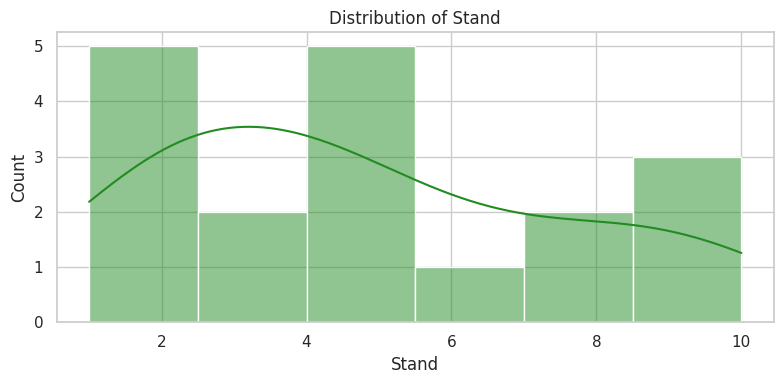

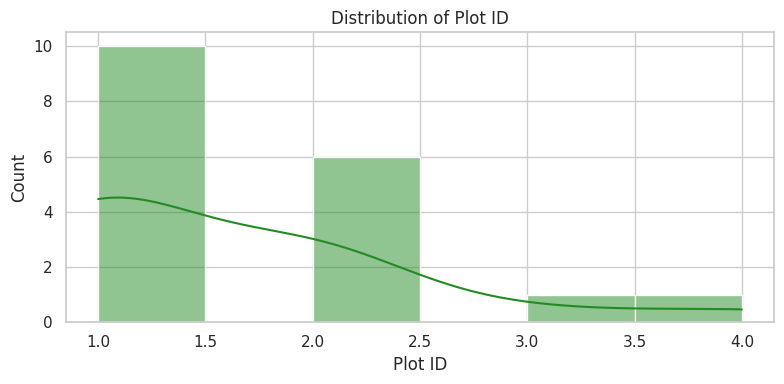

/tmp/ipykernel_749/2381850850.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=plot_meta[col], order=plot_meta[col].value_counts().index, palette='viridis')


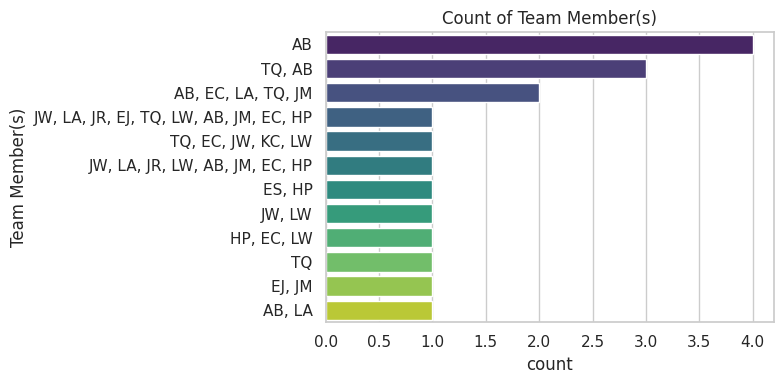

/tmp/ipykernel_749/2381850850.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=plot_meta[col], order=plot_meta[col].value_counts().index, palette='viridis')


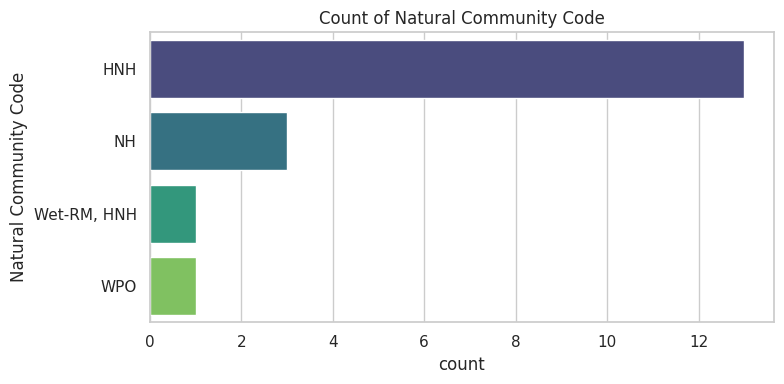

/tmp/ipykernel_749/2381850850.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=plot_meta[col], order=plot_meta[col].value_counts().index, palette='viridis')


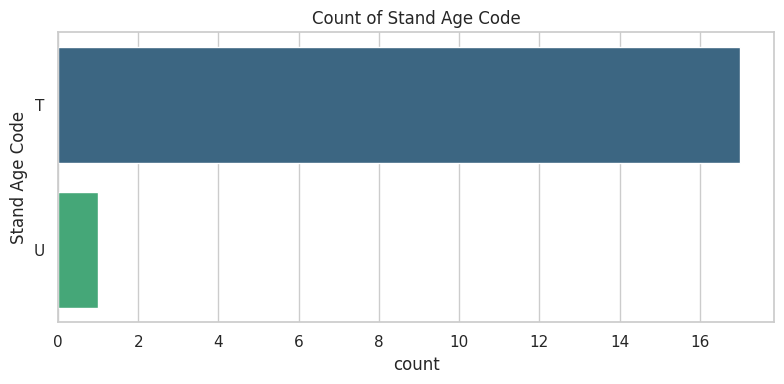

In [6]:
# 3. Load Plot Metadata and visualize variables
plot_meta = pd.read_excel(excel_path, sheet_name='Plot Metadata')
print("Plot Metadata columns:\n", plot_meta.columns.tolist())
print("\nFirst few rows:")
display(plot_meta.head())

# Let's perform a simple automatic visualization of numeric or key categorical variables in Plot Metadata
numeric_cols = plot_meta.select_dtypes(include=['number']).columns.tolist()
categorical_cols = plot_meta.select_dtypes(include=['object', 'category']).columns.tolist()

# Plot distributions
sns.set_theme(style="whitegrid")
for col in numeric_cols[:3]: # Plot up to 3 numeric variables
    plt.figure(figsize=(8, 4))
    sns.histplot(plot_meta[col].dropna(), kde=True, color='forestgreen')
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

for col in categorical_cols[:3]: # Plot up to 3 categorical variables if they aren't unique IDs
    if plot_meta[col].nunique() < 15:
        plt.figure(figsize=(8, 4))
        sns.countplot(y=plot_meta[col], order=plot_meta[col].value_counts().index, palette='viridis')
        plt.title(f'Count of {col}')
        plt.tight_layout()
        plt.show()

In [12]:
plot_meta.head()

,Stand,Plot ID,Date,Team Member(s),Natural Community Code,Stand Age Code,Topography Code,Water (Absent/Present),Water Type (If Applicable),Disturbance Code,Notes
0,1,1,2026-10-23,"JW, LA, JR, EJ, TQ, LW, AB, JM, EC, HP",HNH,T,P,Absent,NaN,"7, 11, 13",NaN
1,2,1,2026-10-23,"JW, LA, JR, LW, AB, JM, EC, HP",NH,T,P,Present,Permanent Stream,"7, 11, 13, 17","Beech bark disease, stumps found (advanced dec..."
2,2,2,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,P,Present,Ephemeral Stream,"5, 13","Beech bark disease, wind"
3,2,3,2026-10-30,"AB, EC, LA, TQ, JM",HNH,T,"CE, CX",Present,Ephemeral and Permanent Streams,4,Beech bark disease
4,2,4,2026-11-05,"TQ, EC, JW, KC, LW",HNH,T,CE,Present,Wetland,"4,11,7,13",NaN


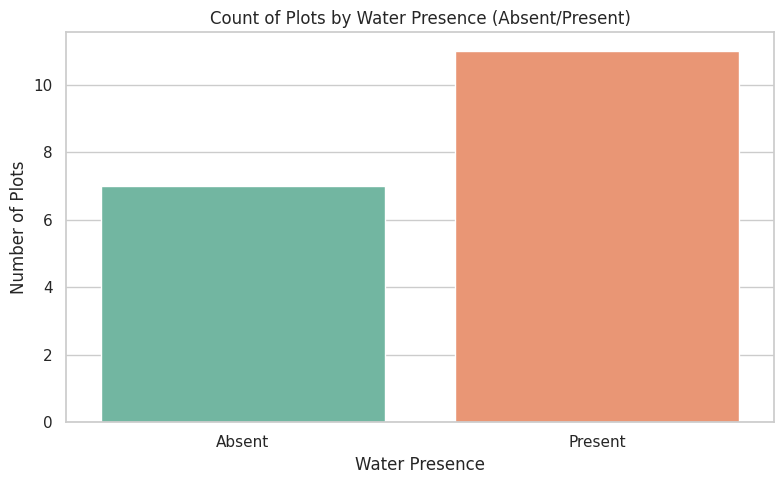

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Set seaborn aesthetic style
sns.set_theme(style="whitegrid")

# 1. Barplot of counts for Water (Absent/Present)
plt.figure(figsize=(8, 5))
sns.countplot(data=plot_meta, x='Water (Absent/Present)', palette='Set2', hue='Water (Absent/Present)', legend=False)
plt.title('Count of Plots by Water Presence (Absent/Present)')
plt.xlabel('Water Presence')
plt.ylabel('Number of Plots')
plt.tight_layout()
plt.show()

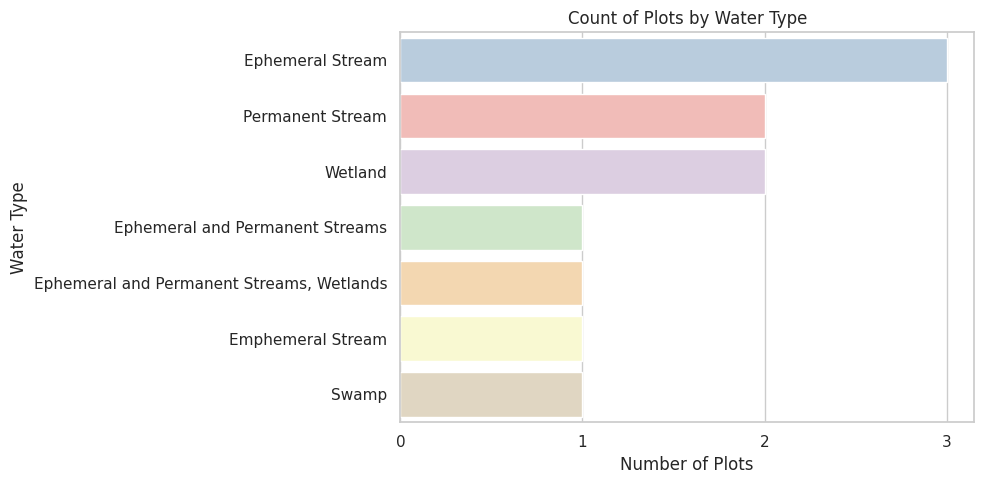

In [11]:
# 2. Barplot of counts for Water Type (If Applicable)
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 5))
# Clean data by removing rows without water type information to keep the plot clean
water_type = plot_meta.dropna(subset=['Water Type (If Applicable)'])
ax = sns.countplot(data=water_type, y='Water Type (If Applicable)', palette='Pastel1', hue='Water Type (If Applicable)', order=water_type['Water Type (If Applicable)'].value_counts().index, legend=False)

# Force the count axis (x-axis in this horizontal plot) to only use integer ticks
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.title('Count of Plots by Water Type')
plt.xlabel('Number of Plots')
plt.ylabel('Water Type')
plt.tight_layout()
plt.show()

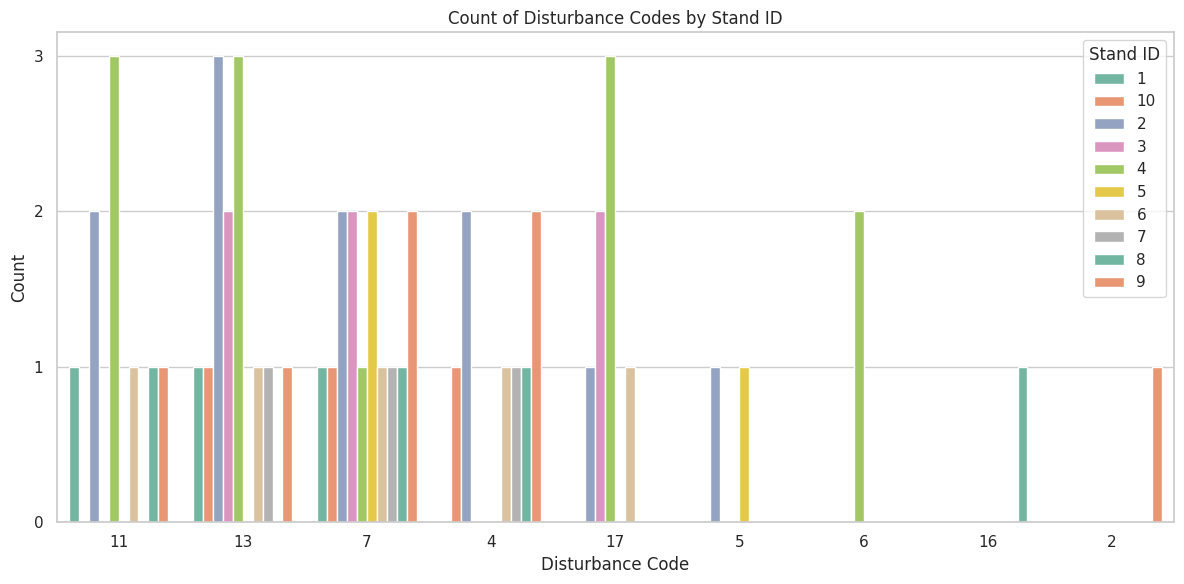

In [14]:
import matplotlib.ticker as ticker

# Ensure plot_meta is loaded and clean
# Drop rows where 'Disturbance Code' or 'Stand' is null
ddf = plot_meta[['Stand', 'Disturbance Code']].dropna().copy()

# Convert Stand to a string/category for discrete plotting categories
ddf['Stand'] = ddf['Stand'].astype(str)

# Split comma-separated codes and explode them into individual rows
ddf['Disturbance Code'] = ddf['Disturbance Code'].astype(str).str.split(',')
exploded_df = ddf.explode('Disturbance Code')

# Strip any accidental whitespace from the codes
exploded_df['Disturbance Code'] = exploded_df['Disturbance Code'].str.strip()

# Remove any remaining empty string values
exploded_df = exploded_df[exploded_df['Disturbance Code'] != '']

# Create a count DataFrame grouped by Stand and Disturbance Code
counts_df = exploded_df.groupby(['Stand', 'Disturbance Code']).size().reset_index(name='Count')

# Plot the data
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=counts_df,
    x='Disturbance Code',
    y='Count',
    hue='Stand',
    palette='Set2'
)

# Ensure only whole numbers are displayed on the count axis (y-axis here)
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.title('Count of Disturbance Codes by Stand')
plt.xlabel('Disturbance Code')
plt.ylabel('Count')
plt.legend(title='Stand')
plt.tight_layout()
plt.show()

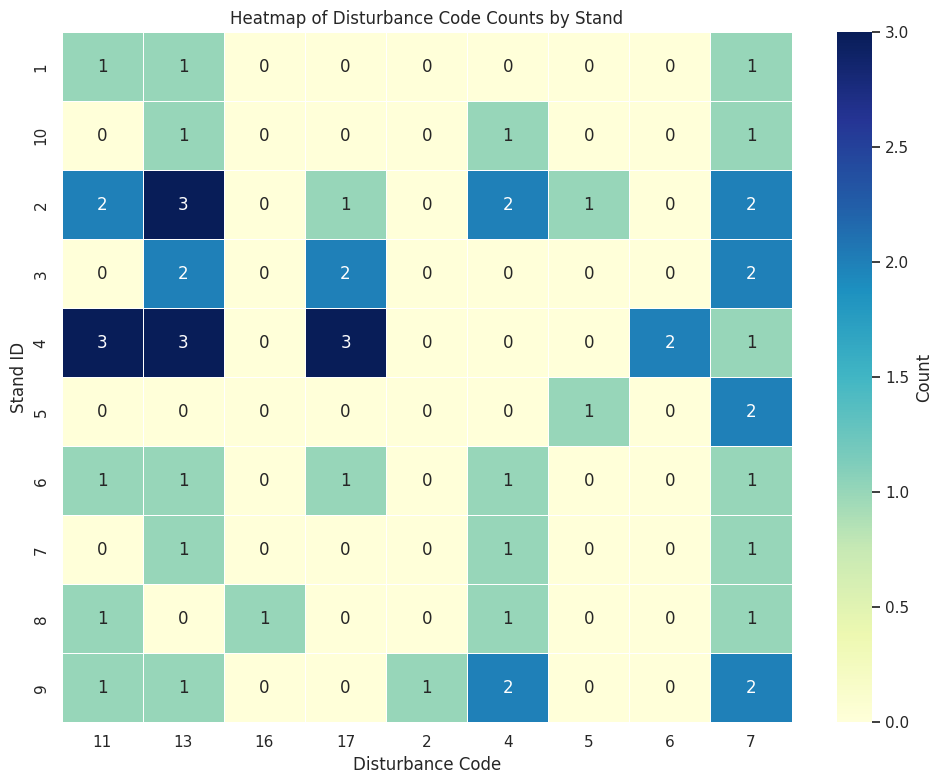

In [17]:
# Prepare pivot table for heatmap (Stands vs Disturbance Codes)
pivot_df = counts_df.pivot(index='Stand', columns='Disturbance Code', values='Count').fillna(0).astype(int)

# --- Method 1: Heatmap ---
plt.figure(figsize=(10, 8))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap='YlGnBu',
    cbar_kws={'label': 'Count'},
    linewidths=0.5,
    fmt='d'
)
plt.title('Heatmap of Disturbance Code Counts by Stand')
plt.xlabel('Disturbance Code')
plt.ylabel('Stand ID')
plt.tight_layout()
plt.show()

/tmp/ipykernel_749/2776833620.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


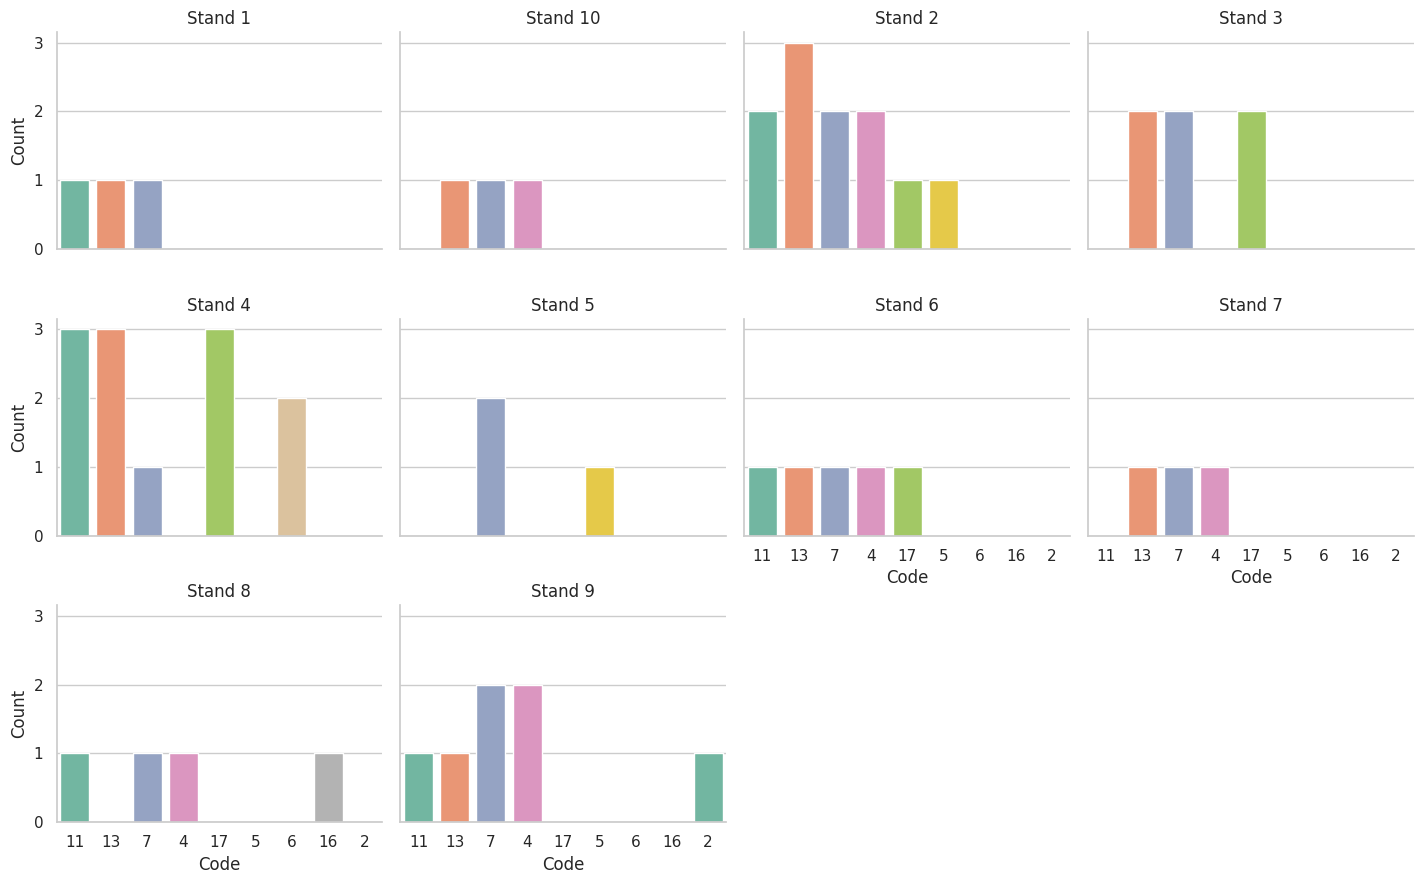

In [15]:
# --- Method 2: Faceted Bar Plot ---
# This splits each stand into its own subplot, which is helpful if the grouped bars feel too crowded.
g = sns.catplot(
    data=counts_df,
    kind='bar',
    x='Disturbance Code',
    y='Count',
    col='Stand',
    col_wrap=4,
    palette='Set2',
    height=3,
    aspect=1.2
)

# Adjust titles and layout
g.set_titles("Stand {col_name}")
g.set_ylabels("Count")
g.set_xlabels("Code")

# Ensure y-axis has only integer ticks on all subplots
for ax in g.axes.flat:
    ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

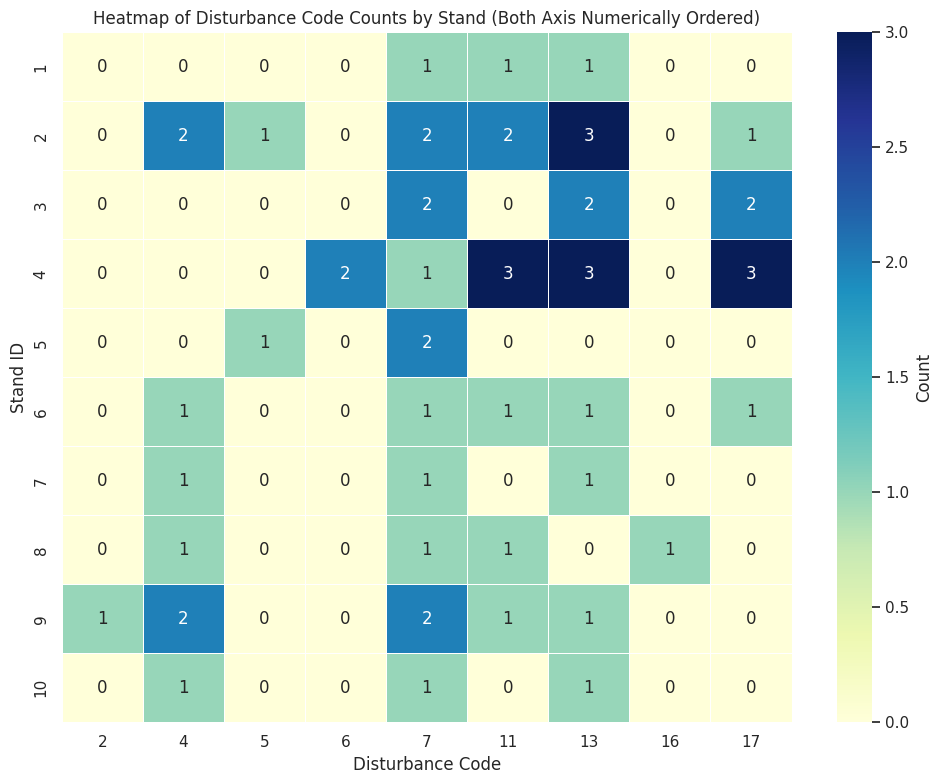

In [19]:
# Clean and prepare the data
ddf = plot_meta[['Stand', 'Disturbance Code']].dropna().copy()
ddf['Stand'] = pd.to_numeric(ddf['Stand']).astype(int)

# Split, explode, and clean
ddf['Disturbance Code'] = ddf['Disturbance Code'].astype(str).str.split(',')
exploded_df = ddf.explode('Disturbance Code')
exploded_df['Disturbance Code'] = exploded_df['Disturbance Code'].str.strip()
exploded_df = exploded_df[exploded_df['Disturbance Code'] != '']

# Convert Disturbance Code to integer for proper numerical sorting
exploded_df['Disturbance Code'] = pd.to_numeric(exploded_df['Disturbance Code']).astype(int)

# Create a count DataFrame and sort it numerically by both Stand and Disturbance Code
counts_df = exploded_df.groupby(['Stand', 'Disturbance Code']).size().reset_index(name='Count')
counts_df = counts_df.sort_values(by=['Stand', 'Disturbance Code'])

# --- Option 1: Heatmap with ordered columns and rows ---
pivot_df = counts_df.pivot(index='Stand', columns='Disturbance Code', values='Count').fillna(0).astype(int)
pivot_df = pivot_df.sort_index(axis=0)  # Sort Stands (rows) numerically
pivot_df = pivot_df.sort_index(axis=1)  # Sort Disturbance Codes (columns) numerically

plt.figure(figsize=(10, 8))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap='YlGnBu',
    cbar_kws={'label': 'Count'},
    linewidths=0.5,
    fmt='d'
)
plt.title('Heatmap of Disturbance Code Counts by Stand (Both Axis Numerically Ordered)')
plt.xlabel('Disturbance Code')
plt.ylabel('Stand ID')
plt.tight_layout()
plt.show()

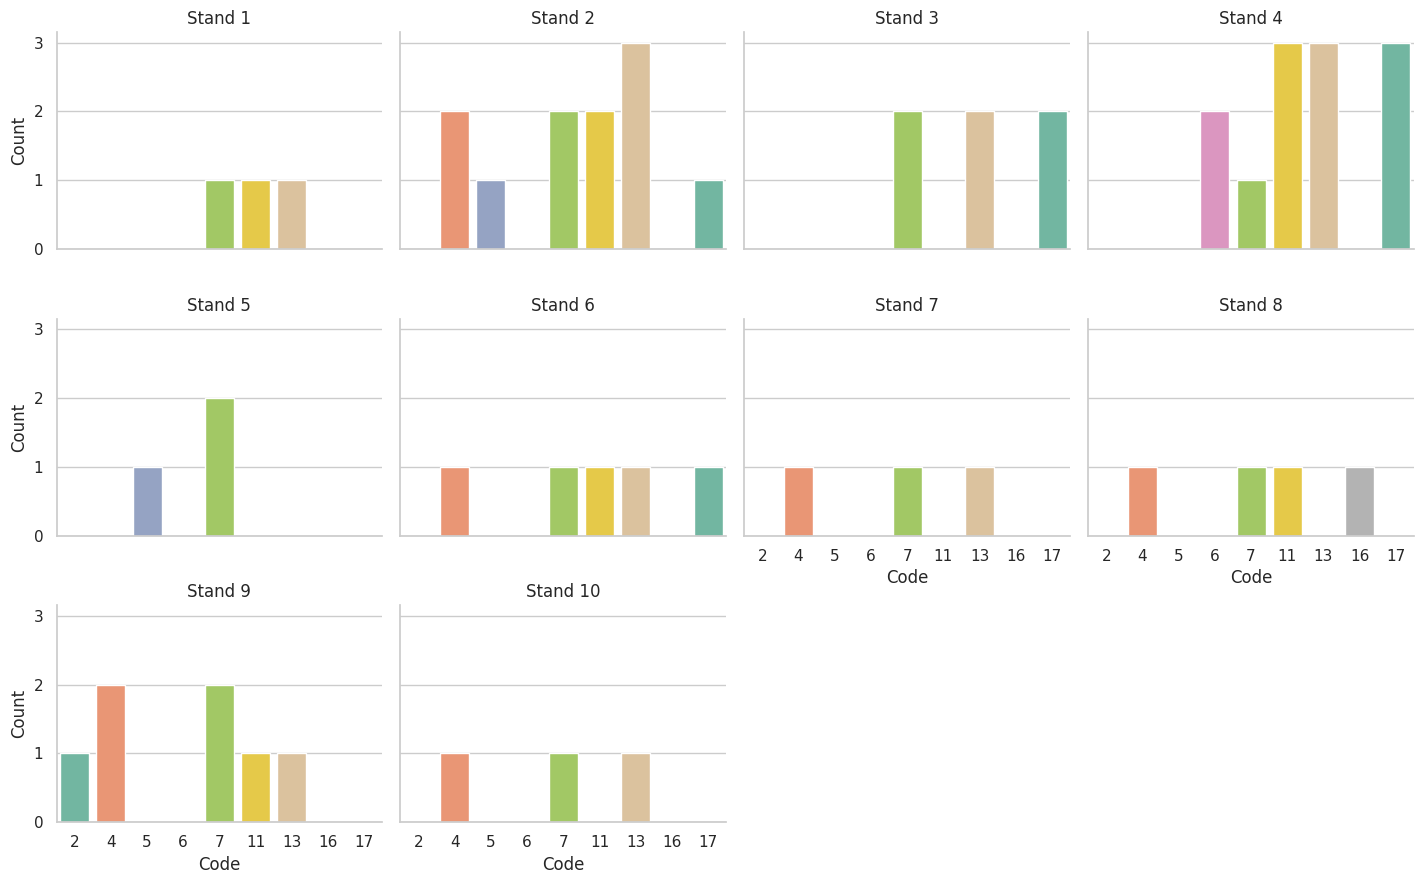

In [20]:
# --- Option 2: Faceted Bar Plot with ordered Disturbance Codes ---
# Get unique disturbance codes sorted numerically to enforce categorical order on the plot
unique_codes = sorted(counts_df['Disturbance Code'].unique())

g = sns.catplot(
    data=counts_df,
    kind='bar',
    x='Disturbance Code',
    y='Count',
    col='Stand',
    col_wrap=4,
    palette='Set2',
    hue='Disturbance Code',
    order=unique_codes,
    legend=False,
    height=3,
    aspect=1.2
)

# Adjust titles and layout
g.set_titles("Stand {col_name}")
g.set_ylabels("Count")
g.set_xlabels("Code")

# Ensure y-axis has only integer ticks on all subplots
for ax in g.axes.flat:
    ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

##Organic Cover

In [30]:
# Load the Subplot Hydrology and Surface CSV into 'hydro'
hydro = pd.read_csv('/content/forest_inventory_csvs/Subplot_Hydrology_and_Surface.csv')

hydro.head()

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Water (Present/Absent),Water Type (If Applicable),"O Horizon Depth (Litter, Duff, Humus) (in)",Surface Organic Cover (%) Code,Surface Inorganic Cover (%) Code,Notes
0,1,1,1,2026-10-23,"TQ, EJ, EC, JM, JW, LA, HP, LW, AB",Absent,NaN,14.0,4,2,NaN
1,2,1,1,2026-10-23,"JW, JM, LA, LW",Absent,NaN,3.0,4,1,NaN
2,2,1,2,2026-10-23,"JW, JM, LA, LW",Present,Permanent Stream,14.0,2,2,NaN
3,2,1,3,2026-10-23,"JW, JM, LA, LW",Absent,NaN,8.5,4,1,NaN
4,2,2,1,2026-10-28,LA,Absent,NaN,8.0,4,2,NaN


In [33]:
hydro['Stand ID'] = hydro['Stand ID'].astype('category')

/tmp/ipykernel_749/3186288132.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


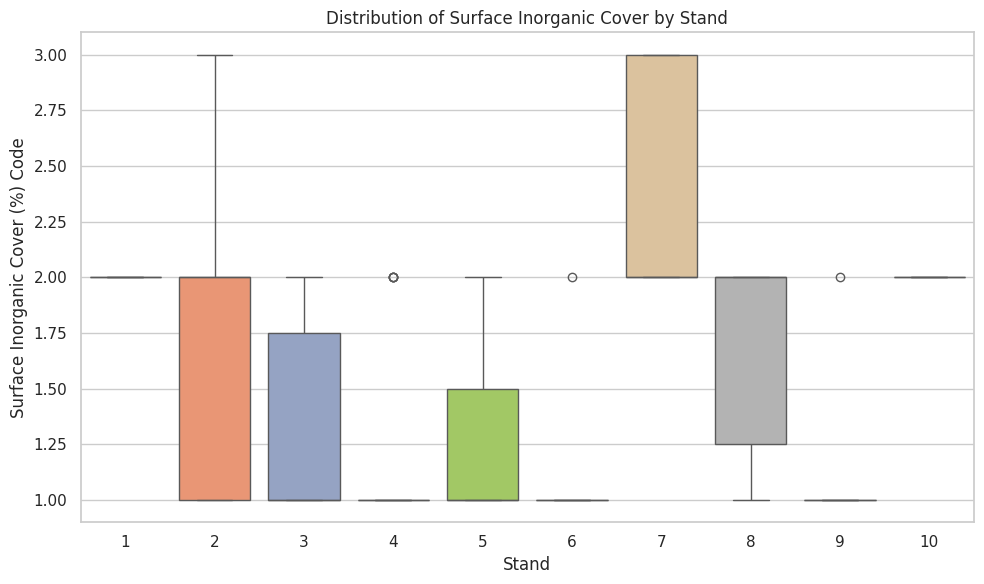

In [34]:
# Ensure plot style
sns.set_theme(style="whitegrid")

# Plot distribution
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=hydro,
    x='Stand ID',
    y='Surface Inorganic Cover (%) Code',
    palette='Set2'
)

plt.title('Distribution of Surface Inorganic Cover by Stand')
plt.xlabel('Stand')
plt.ylabel('Surface Inorganic Cover (%) Code')
plt.tight_layout()
plt.show()

In [35]:
# Calculate the average inorganic cover grouped by Stand ID
avg_cover = hydro.groupby('Stand ID', observed=False)['Surface Inorganic Cover (%) Code'].mean().reset_index()

# Rename columns as requested
avg_cover.columns = ['Stand', 'Average Surface Inorganic Cover (%) Code']

# Display the table
display(avg_cover)

,Stand,Average Surface Inorganic Cover (%) Code
0,1,2.000000
1,2,1.666667
2,3,1.333333
3,4,1.181818
4,5,1.333333
5,6,1.142857
6,7,2.333333
7,8,1.666667
8,9,1.200000
9,10,2.000000


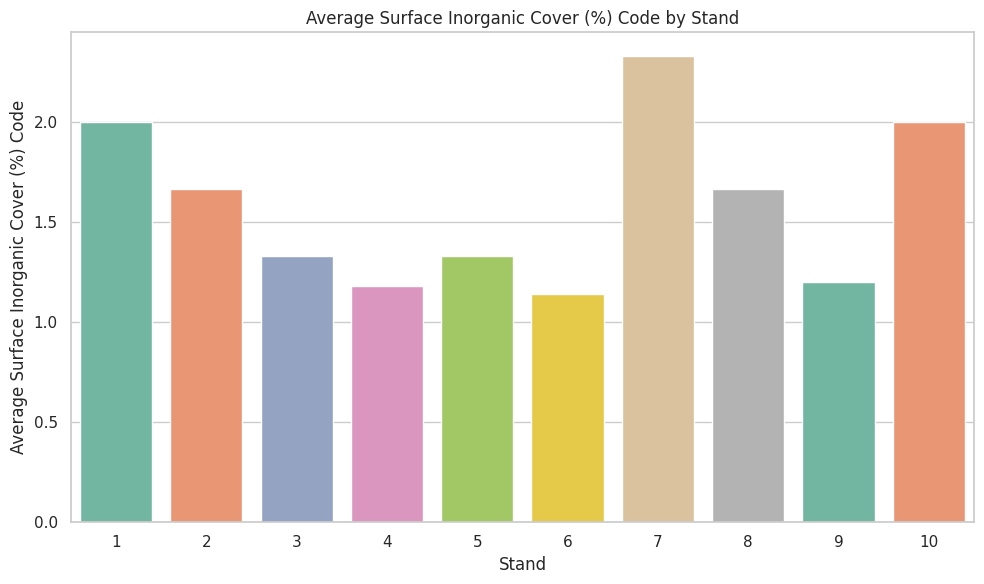

In [36]:
# Plot the average inorganic cover by Stand
plt.figure(figsize=(10, 6))
sns.barplot(
    data=avg_cover,
    x='Stand',
    y='Average Surface Inorganic Cover (%) Code',
    palette='Set2',
    hue='Stand',
    legend=False
)

plt.title('Average Surface Inorganic Cover (%) Code by Stand')
plt.xlabel('Stand')
plt.ylabel('Average Surface Inorganic Cover (%) Code')
plt.tight_layout()
plt.show()

###Snag/damage code analysis

In [40]:
damwood = pd.read_csv('/content/forest_inventory_csvs/Subplot_Woody_Species_Data.csv')
damwood.head()

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Tree ID,Species Code,Tree Status,DBH (in),Estimated Tree Height (m),Estimated Tree Height (ft),Crown Class Code,Damage Type Code,Snag Decay Class (If Applicable),Notes
0,1,1,1,2026-10-23,"EJ, TQ",1.0,YB,AL,8.30,25.0,82.020998,Dominant,NaN,NaN,NaN
1,1,1,1,2026-10-23,"EJ, TQ",2.0,EH,AL,8.25,10.0,32.808399,Suppressed,NaN,NaN,NaN
2,1,1,1,2026-10-23,"LW, AB, HB",3.0,AB,DA,13.52,13.5,44.291339,Dominant,20,NaN,Base of trunk split
3,1,1,1,2026-10-23,"EC, HP, AB, LW",4.0,AB,DA,5.98,10.0,32.808399,Codominant,20,NaN,Bark split
4,1,1,1,2026-10-23,"JW, JR, HP",5.0,EH,AL,11.80,5.5,18.044619,Overtopped,NaN,NaN,NaN


In [41]:
damwood['Stand ID'] = damwood['Stand ID'].astype('category')

In [42]:
# Calculate the proportion of 'DE' in 'Tree Status' by 'Stand ID'
# We find the total count of observations and the count of 'DE' observations per stand
status_by_stand = damwood.groupby('Stand ID', observed=False)['Tree Status']

total_counts = status_by_stand.count()
de_counts = status_by_stand.apply(lambda x: (x == 'DE').sum())

# Calculate proportion
de_proportions = (de_counts / total_counts).reset_index(name='Proportion of DE')

# Rename columns for clarity
de_proportions.columns = ['Stand', 'Proportion of DE']

# Display the table
display(de_proportions)

,Stand,Proportion of DE
0,1,0.142857
1,2,0.115385
2,3,0.093750
3,4,0.043062
4,5,0.125000
5,6,0.083333
6,7,0.194805
7,8,0.062500
8,9,0.041667
9,10,0.142857


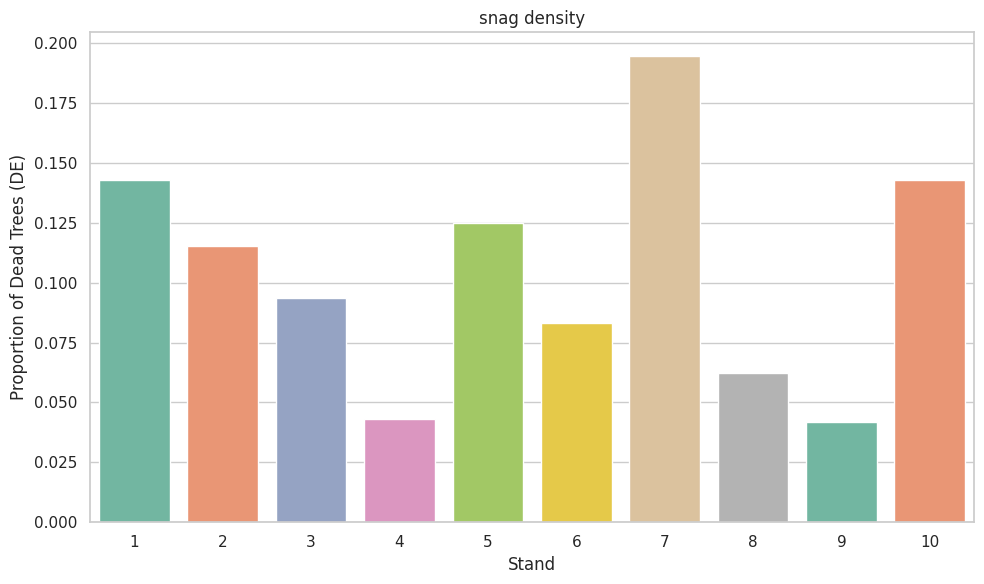

In [43]:
# Plot the proportion of DE (Dead) trees by Stand (Snag Density)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=de_proportions,
    x='Stand',
    y='Proportion of DE',
    palette='Set2',
    hue='Stand',
    legend=False
)

plt.title('snag density')
plt.xlabel('Stand')
plt.ylabel('Proportion of Dead Trees (DE)')
plt.tight_layout()
plt.show()

##Invasives?

In [44]:
herbs= pd.read_csv('/content/forest_inventory_csvs/Subplot_Herbaceous_Species_Data.csv')
herbs.head()

,Stand ID,Plot ID,Subplot ID,Date,Team Member(s),Species ID,Invasive (Y/N),General Phenological State,Damage Type Code,Percent Cover (%),Notes
0,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",PRP,N,1,NaN,1,NaN
1,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",SF,N,1,NaN,1,NaN
2,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",XMF,N,1,NaN,1,NaN
3,1,1,1,2026-10-23,"EC, HP, JM, LW, AB, JW, JR, LA",INT,N,1,NaN,1,NaN
4,2,1,1,2026-10-23,"AB, JR, EC, HP",PRP,N,1,NaN,1,NaN


In [45]:
herbs['Stand ID'] = herbs['Stand ID'].astype('category')

In [46]:
# Count the number of 'Y' instances in the 'Invasive (Y/N)' column
invasive_count = (herbs['Invasive (Y/N)'] == 'Y').sum()
print(f"Number of invasive instances (Y): {invasive_count}")

Number of invasive instances (Y): 1


Well I guess that's a dead end for now